In [1]:
!git clone https://github.com/ronnaug/scMimic
%cd scMimic

Cloning into 'scMimic'...
remote: Enumerating objects: 23, done.
remote: Counting objects: 100% (23/23), done.
remote: Compressing objects: 100% (22/22), done.
remote: Total 23 (delta 8), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (23/23), 24.45 KiB | 4.89 MiB/s, done.
Resolving deltas: 100% (8/8), done.
/content/scMimic


In [2]:
pip install -r requirements.txt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 36.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 75.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 50.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 28.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 42.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 54.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 32.5 MB/s  0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27/27 [infercnvpy]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible

In [4]:
import scanpy as sc
from scMimic import run_mimic_detector_pipeline
from visualization import plot_mimicry_results

In [5]:
!gunzip -f /content/scMimic/resources/gencode.v50.basic.annotation.gtf.gz

In [6]:
import numpy as np

# 1. Load a built-in, preprocessed Scanpy dataset (~2600 cells, 1800 genes)
adata_demo = sc.datasets.pbmc3k_processed()

# 2. Map population names to the standard names used in Mimic references.
mapping = {
    "CD4 T cells": "T cell",
    "CD8 T cells": "T cell",
    "B cells": "B cell",
    "NK cells": "NK cell",
    "CD14+ Monocytes": "Macrophage",
    "FCGR3A+ Monocytes": "Macrophage",
    "Dendritic cells": "Dendritic cell",
    "Megakaryocytes": "Epithelial",  # Simulating a target tumor cluster for testing
}
adata_demo.obs["Celltype"] = adata_demo.obs["louvain"].astype(str).map(mapping).fillna("T cell")

# We’ll take a subset of 400 cells (including all "Epithelial" cells plus 70 reference cells each) for a quick run-through.
epi_idx = adata_demo.obs_names[adata_demo.obs["Celltype"] == "Epithelial"].tolist()
ref_idx = (
    adata_demo.obs[adata_demo.obs["Celltype"] != "Epithelial"]
    .groupby("Celltype", group_keys=False, observed=True)
    .apply(lambda x: x.sample(min(len(x), 70), random_state=42))
    .index.tolist()
)
adata_sub = adata_demo[epi_idx + ref_idx].copy()

# We add a synthetic CNV shift (amplification of chr7) to the target cluster so that it passes the CNV filter.
X_mat = adata_sub.X.toarray() if hasattr(adata_sub.X, "toarray") else np.array(adata_sub.X, copy=True)
is_epi = (adata_sub.obs["Celltype"] == "Epithelial").values
X_mat[is_epi, :150] += 1.5
adata_sub.X = X_mat

  0%|          | 0.00/23.5M [00:00<?, ?B/s]

[INFO] Starting MimicDetector pipeline...
[INFO] Parsing GENCODE gene coordinates from: resources/gencode.v50.basic.annotation.gtf
[INFO] Mapping genes to chromosomal coordinates...
[INFO] Using diploid reference populations: ['T cell', 'B cell', 'NK cell', 'Macrophage']
[INFO] Running chromosomal CNV inference (infercnvpy)...


  0%|          | 0/1 [00:00<?, ?it/s]

[INFO] Extracted CNV matrix with shape: (332, 108)
[INFO] Computing per-cell genomic instability index...
[INFO] CNV baseline median: 0.0891 | MAD: 0.0200 | Malignancy threshold: 0.0850
[INFO] Formatting expression matrix for de novo regulon inference...
[INFO] Active transcription factors matched in expression matrix: 141
[INFO] Inferring de novo regulons across 1589 target genes on 2 cores...


/usr/local/lib/python3.13/dist-packages/scanpy/preprocessing/_highly_variable_genes.py:417: RuntimeWarning: invalid value encountered in log
  dispersion = np.log(dispersion)
/content/scMimic/scMimic.py:239: UserWarning: `n_top_genes` (=1630) > number of normalized dispersions (=1588), returning all genes with normalized dispersions.
  sc.pp.highly_variable_genes(adata_hvg, n_top_genes=n_top, flavor="seurat")


[INFO] De novo regulatory network built. Total edges: 107117
[INFO] Extracting lineage-specific de novo TF signatures...
[INFO] Computing hybrid regulon and surface marker activity scores...
[INFO] Screening cell populations for cross-lineage mimicry...

[SUMMARY] Population verdict distribution:
gsea_mimicry_verdict
Healthy B cell (Validated via CNV)                                                      70
Healthy Macrophage (Validated via CNV)                                                  70
Healthy NK cell (Validated via CNV)                                                     70
Healthy T cell (Validated via CNV)                                                      70
Full Phenotype Switch: Canonical: Neuronal/Neuroendocrine (masked as Dendritic cell)    15
Malignant Dendritic cell (Low Regulon Specificity)                                      12
Malignant Epithelial (Low Regulon Specificity)                                          10
Healthy Dendritic cell (Validated via CNV)  

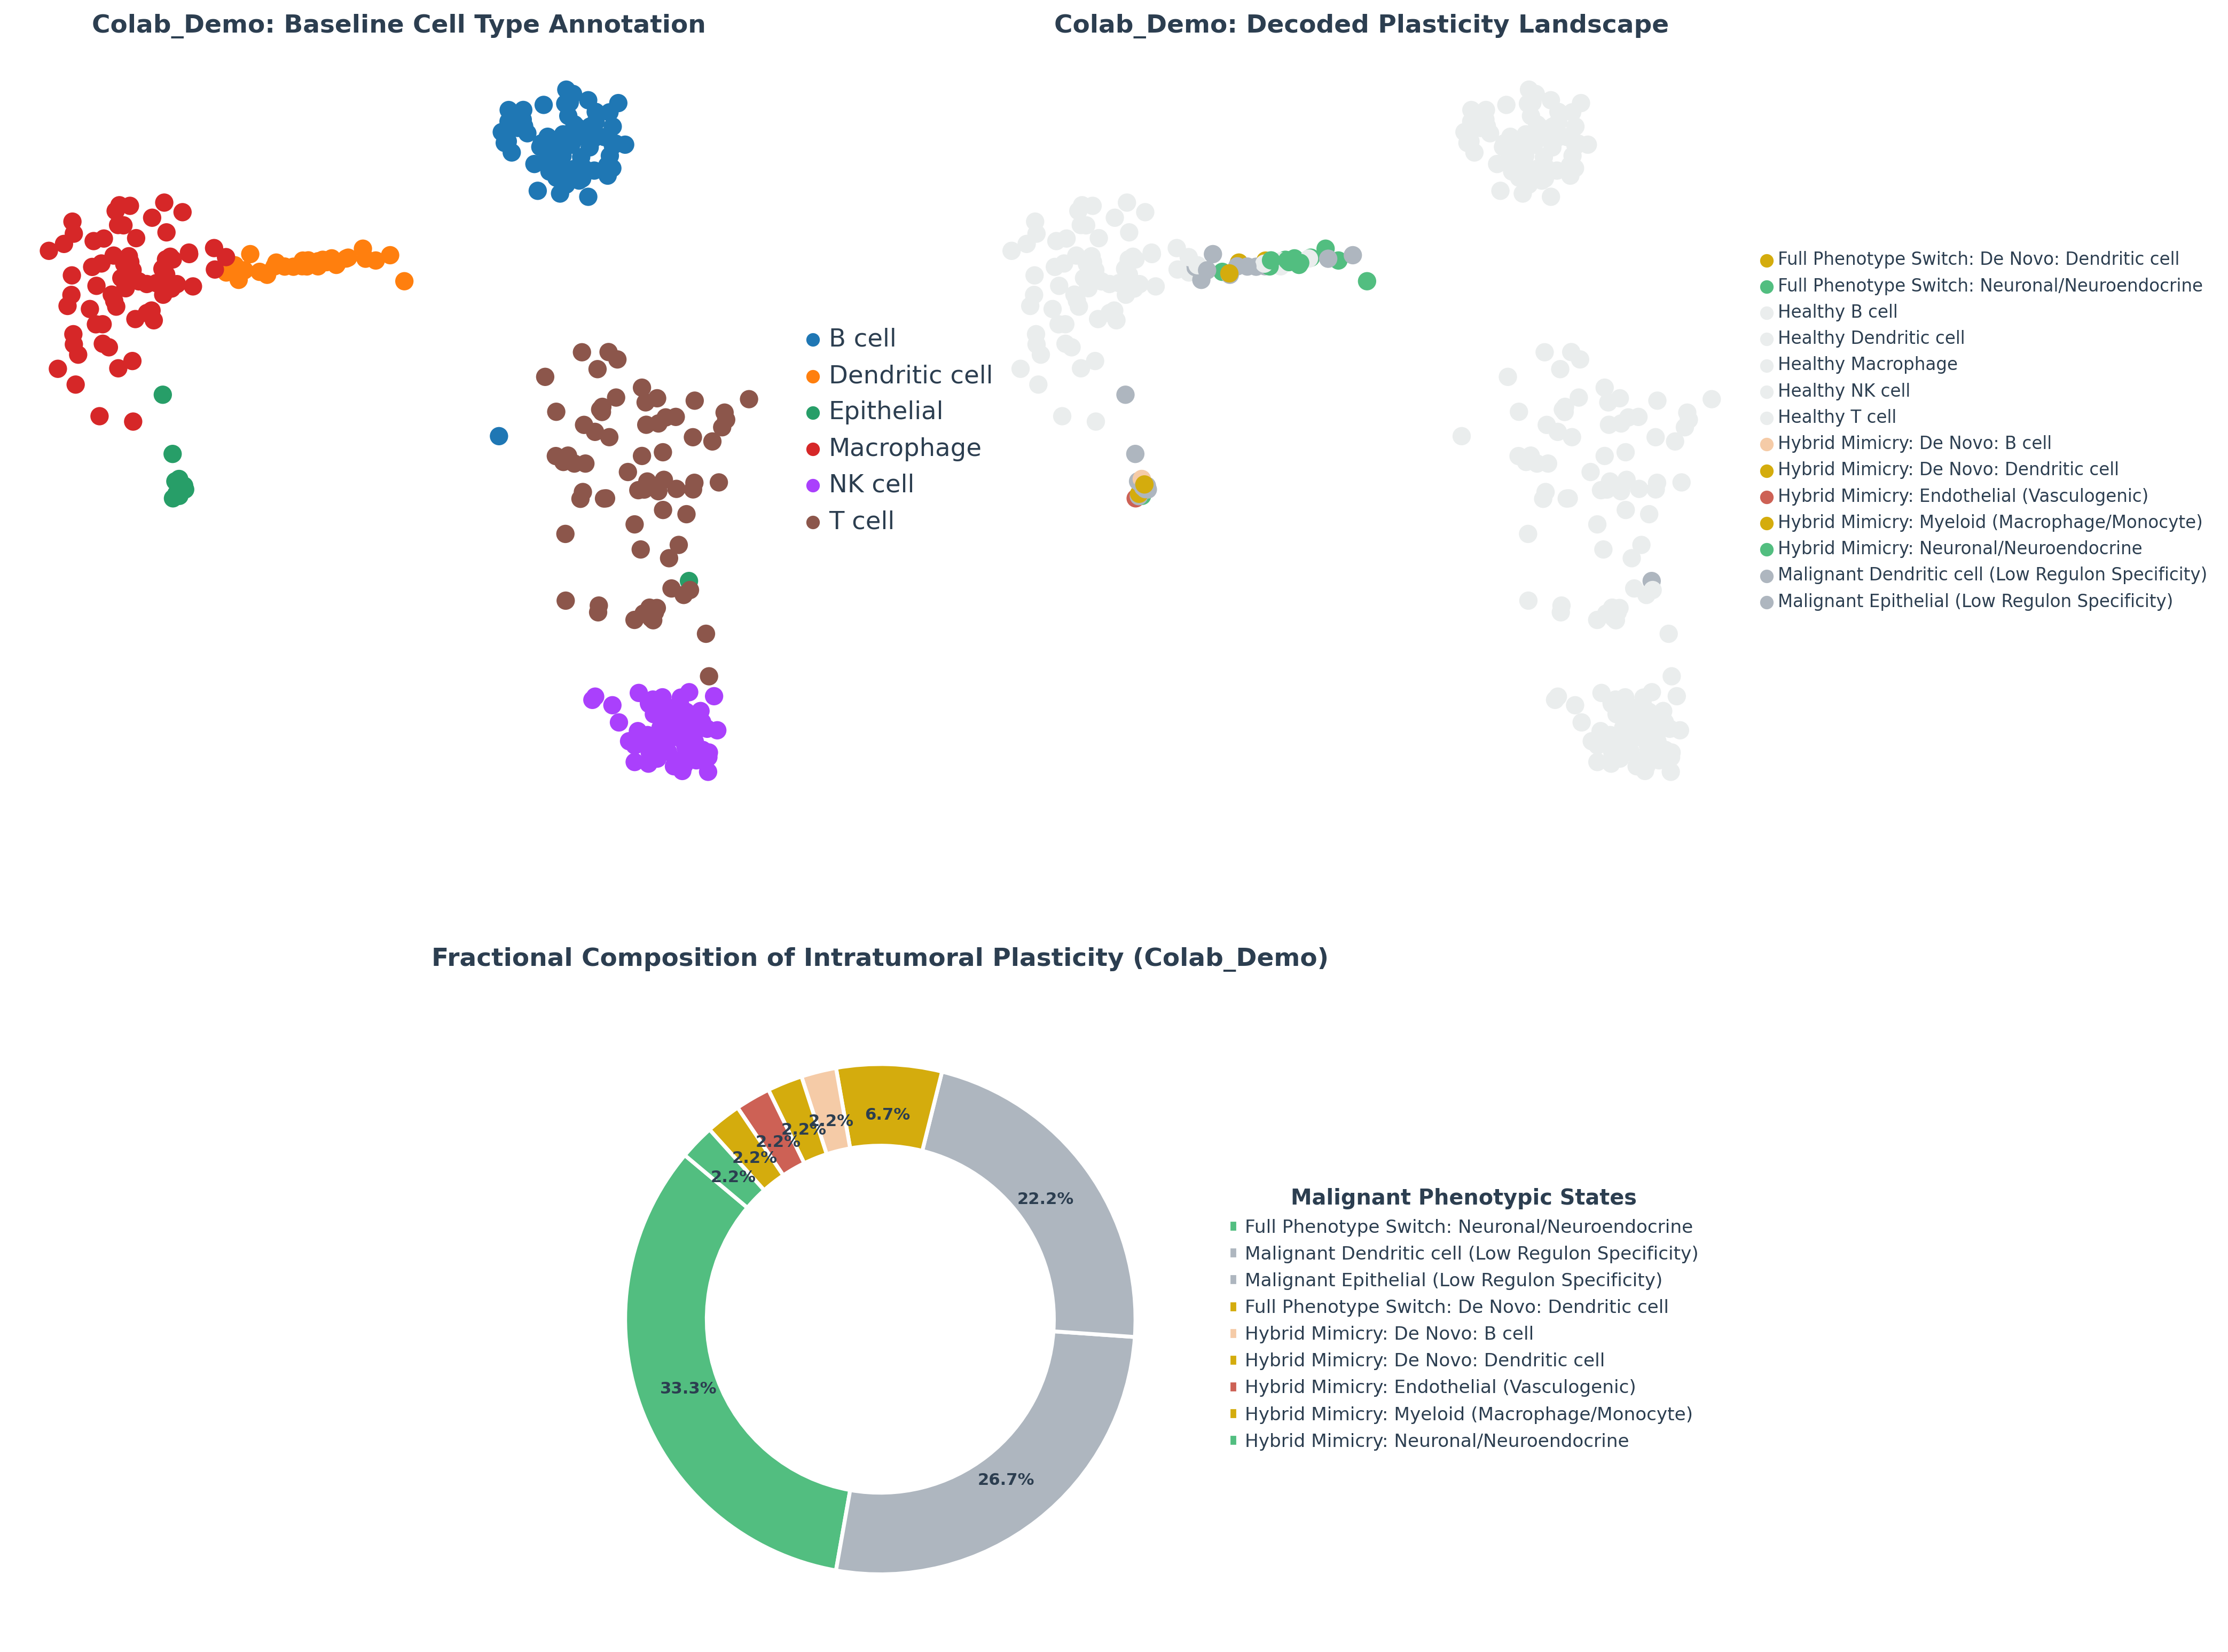

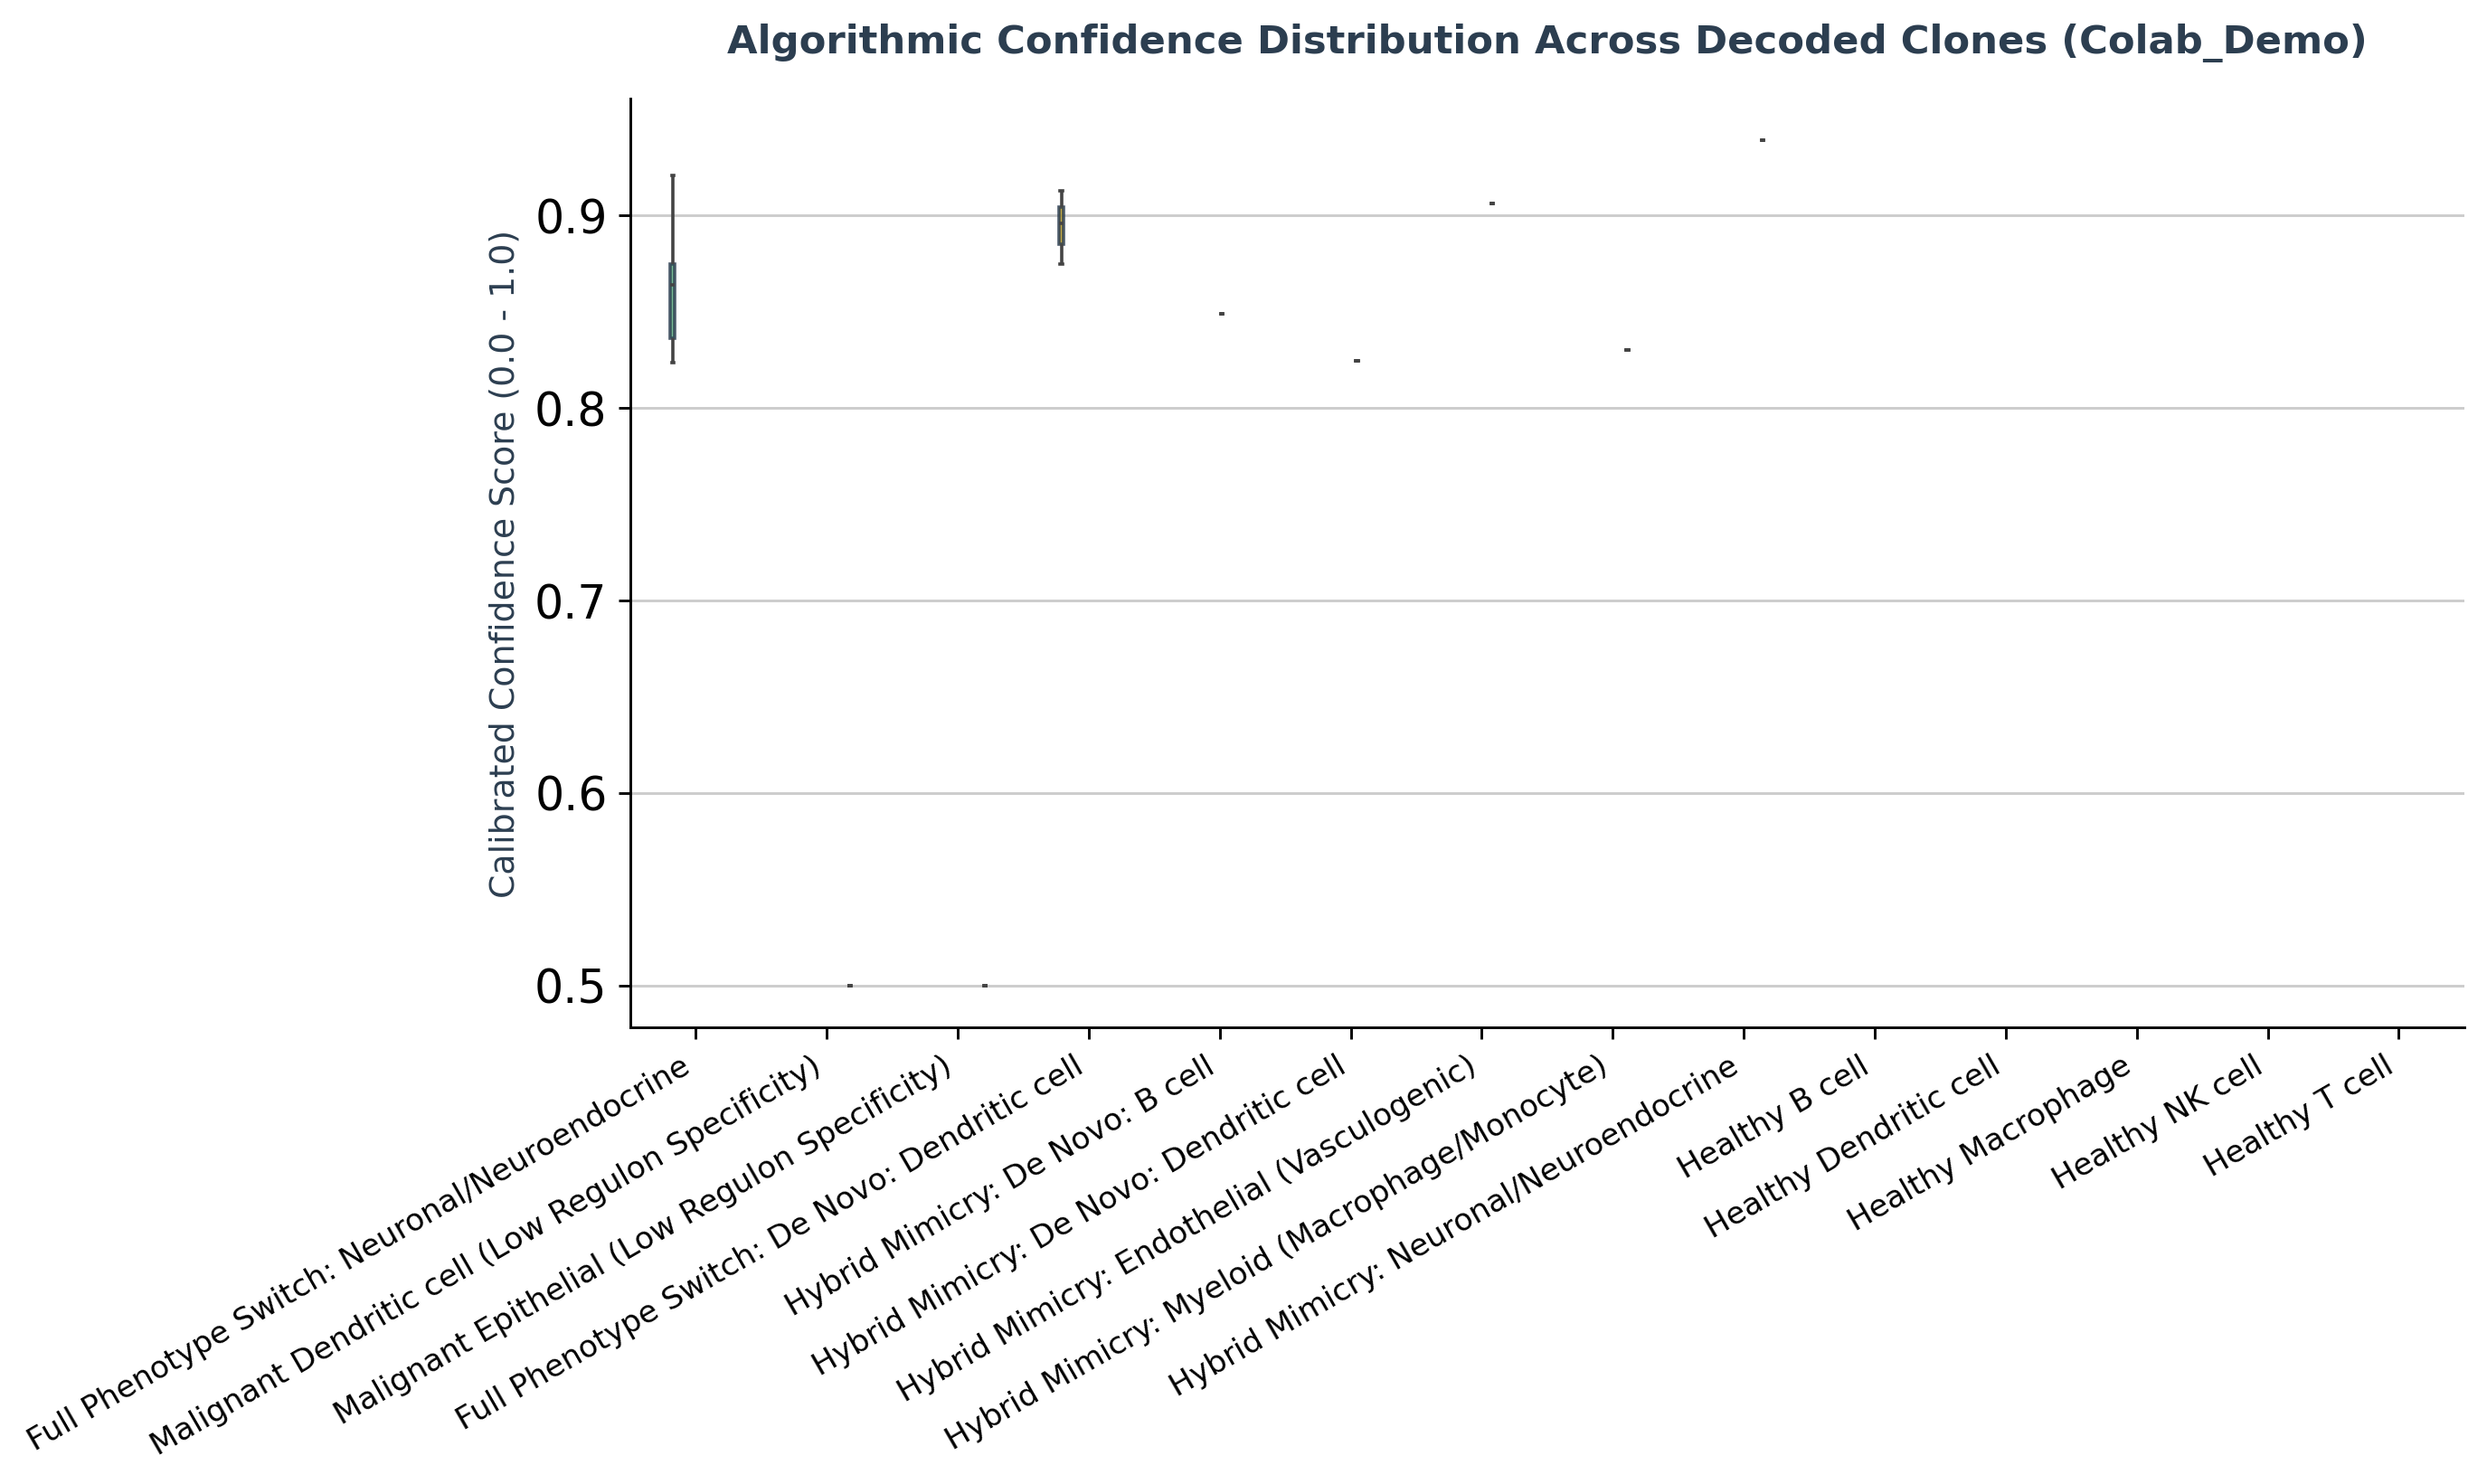

In [8]:
# 3. Launching the full scMimic pipeline
adata_out = run_mimic_detector_pipeline(
    adata=adata_sub,
    gtf_path="resources/gencode.v50.basic.annotation.gtf",
    tf_list_path="resources/hs_hgnc_tfs.txt",
    celltype_col="Celltype",
    malignant_cell_types=["Epithelial"],
    n_jobs=2,  # В бесплатном Colab обычно 2 ядра CPU
)

# 4. Checking the rendering of charts
plot_mimicry_results(
    adata=adata_out,
    save_dir="./results",
    project_name="Colab_Demo",
    celltype_col="Celltype",
)